In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

In [2]:
PROCESSED = "../Data/Processed/"

#in-memory duckdb connection (nothing is written to disk)
con = duckdb.connect()

#views over the cleaned parquet files (column types are stored in the files)
con.execute(f"CREATE OR REPLACE VIEW orders AS SELECT * FROM read_parquet('{PROCESSED}orders_clean.parquet')");

### Order Status Analysis (Q1 and Q2)

In [3]:
# Calculate the total number of orders
total = con.sql(""" 
    select count(*) as total
    from orders
 """).df()

print(f"Total orders: {total.iloc[0, 0]}")

Total orders: 99441


In [4]:
#number of orders for each order_status
order_status = con.sql("""
    select order_status, count(*) as status_number
    from orders
    group by order_status
    order by status_number desc
""").df()

#percent of each status = its count / total count * 100
order_status["status_percent"] = order_status["status_number"] / order_status["status_number"].sum() * 100

print("number of each order_status:")
display(order_status.round(2))

number of each order_status:


,order_status,status_number,status_percent
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


In [5]:
#group statuses by what they mean for the customer
status_group = {
    "delivered": "delivered",
    "canceled": "failed", "unavailable": "failed",
    "shipped": "in progress", "invoiced": "in progress", "processing": "in progress",
    "approved": "in progress", "created": "in progress",
}
order_status["group"] = order_status["order_status"].map(status_group)

group_summary = (order_status.groupby("group")[["status_number", "status_percent"]].sum()
                 .sort_values("status_number", ascending=False))
display(group_summary.round(2))

failed = group_summary.loc["failed"]
print(f"non-fulfilment rate (canceled + unavailable): {failed['status_percent']:.2f}% ({int(failed['status_number']):,} orders)")

,status_number,status_percent
group,,
delivered,96478,97.02
in progress,1729,1.74
failed,1234,1.24


non-fulfilment rate (canceled + unavailable): 1.24% (1,234 orders)


In [6]:
#status by purchase month: statuses are a snapshot taken when the data was extracted
status_by_month = con.sql("""
    select date_trunc('month', order_purchase_timestamp) as month_start,
           count(*) as orders,
           sum(case when order_status in ('canceled', 'unavailable') then 1 else 0 end) * 100.0 / count(*) as failed_pct,
           sum(case when order_status in ('shipped', 'invoiced', 'processing', 'approved', 'created') then 1 else 0 end) * 100.0 / count(*) as in_progress_pct
    from orders
    group by month_start
    order by month_start
""").df()

display(status_by_month.round({"failed_pct": 2, "in_progress_pct": 2}))

,month_start,orders,failed_pct,in_progress_pct
0,2016-09-01,4,50.00,25.00
1,2016-10-01,324,9.57,8.64
2,2016-12-01,1,0.00,0.00
3,2017-01-01,800,1.62,4.62
4,2017-02-01,1780,3.48,3.65
5,2017-03-01,2682,2.42,2.65
6,2017-04-01,2404,1.12,3.08
7,2017-05-01,3700,1.62,2.54
8,2017-06-01,3245,1.23,2.16
9,2017-07-01,4026,1.99,1.84


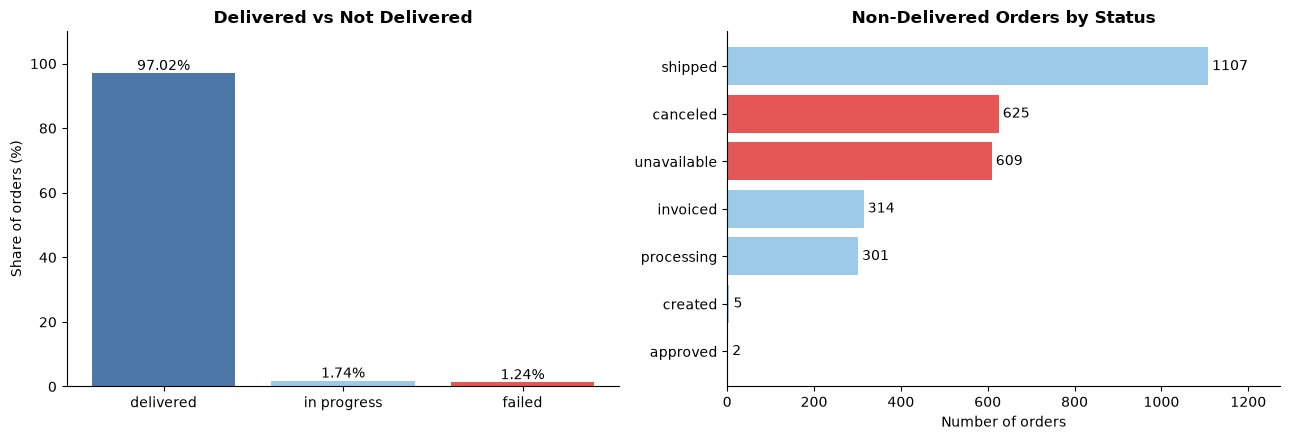

In [7]:
#chart: delivered vs not delivered (left), then the non-delivered statuses on their own (right)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

#left: share of each group (group_summary is already sorted: delivered, in progress, failed)
bars = ax1.bar(group_summary.index, group_summary["status_percent"],
               color=["#4C78A8", "#9ECAE9", "#E45756"])
ax1.bar_label(bars, fmt="%.2f%%")
ax1.set_title("Delivered vs Not Delivered", fontweight="bold")
ax1.set_ylabel("Share of orders (%)")
ax1.set_ylim(0, 110)

#right: every status except delivered (red = failed, light blue = in progress)
not_delivered = order_status[order_status["order_status"] != "delivered"]
colors = not_delivered["group"].map({"failed": "#E45756", "in progress": "#9ECAE9"})
bars = ax2.barh(not_delivered["order_status"], not_delivered["status_number"], color=colors)
ax2.bar_label(bars, padding=3)
ax2.invert_yaxis()   #biggest status on top
ax2.set_title("Non-Delivered Orders by Status", fontweight="bold")
ax2.set_xlabel("Number of orders")
ax2.set_xlim(0, not_delivered["status_number"].max() * 1.15)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Order Status Analysis – Conclusion

The Olist dataset contains **99,441 orders**, of which **97.02% (96,478)** were delivered.

**Non-delivered orders (2.98%) fall into two very different groups:**
- **Failed (1.24%, 1,234 orders):** `canceled` (625) and `unavailable` (609). "Unavailable" orders also failed (the product could not be supplied), so the non-fulfilment rate is **1.24%**, about twice the 0.63% cancellation rate alone.
- **In progress (1.74%, 1,729 orders):** `shipped`, `invoiced`, `processing`, `approved`, and `created`. Statuses are a snapshot taken when the data was extracted, so most of these orders were simply not finished yet.

**By purchase month:** within the valid window (Jan 2017 to Aug 2018), the failed share stays between about 0.3% and 3.5% per month, and the in-progress share between about 0.8% and 4.6%. Outside it, the shares are extreme (Sep 2018: 93.75% failed; Oct 2018: 100%), which is one more sign that those months are artefacts of the data cutoff.

**Business Insight:**

Olist delivers almost all of its orders. The real failure rate is 1.24%, and about half of it comes from unavailable products rather than customer cancellations, so stock availability is worth investigating alongside cancellations.

### Monthly Order Analysis (Q3)

In [8]:
#number of orders in each month
monthly_order = con.sql("""
    select order_year, order_month, count(*) as orders_count
    from orders
    group by order_year, order_month
    order by order_year, order_month
""").df()

#a real date column (first day of the month), so months sort and plot in order
monthly_order["month_start"] = pd.to_datetime(dict(year=monthly_order["order_year"],
                                                   month=monthly_order["order_month"], day=1))
monthly_order["month_abbr"] = monthly_order["month_start"].dt.strftime("%b")   #Jan, Feb, ...

print("number of orders for each month:")
display(monthly_order[["month_start", "month_abbr", "orders_count"]])

number of orders for each month:


,month_start,month_abbr,orders_count
0,2016-09-01,Sep,4
1,2016-10-01,Oct,324
2,2016-12-01,Dec,1
3,2017-01-01,Jan,800
4,2017-02-01,Feb,1780
5,2017-03-01,Mar,2682
6,2017-04-01,Apr,2404
7,2017-05-01,May,3700
8,2017-06-01,Jun,3245
9,2017-07-01,Jul,4026


In [9]:
#valid analysis window (months before/after it have incomplete data, see below)
START = pd.Timestamp("2017-01-01")
END   = pd.Timestamp("2018-08-01")   #last valid month (month-start date)

#orders per month as a series with the month as index
timeline = monthly_order.set_index("month_start")["orders_count"]

#Nov 2016 has no orders at all, so it has no row: add it back with 0 so the chart doesn't skip it
all_months = pd.date_range(timeline.index.min(), timeline.index.max(), freq="MS")
timeline = timeline.reindex(all_months, fill_value=0)

#only the valid months
valid = timeline[START:END]

In [10]:
max_date, max_val = valid.idxmax(), valid.max()
min_date, min_val = valid.idxmin(), valid.min()

print("number of orders in valid range date:")
display(valid.to_frame())
print(f"month with the most orders  : {max_date.strftime('%B %Y')} with {max_val:,} orders")
print(f"month with the fewest orders: {min_date.strftime('%B %Y')} with {min_val:,} orders")

number of orders in valid range date:


,orders_count
2017-01-01,800
2017-02-01,1780
2017-03-01,2682
2017-04-01,2404
2017-05-01,3700
2017-06-01,3245
2017-07-01,4026
2017-08-01,4331
2017-09-01,4285
2017-10-01,4631


month with the most orders  : November 2017 with 7,544 orders
month with the fewest orders: January 2017 with 800 orders


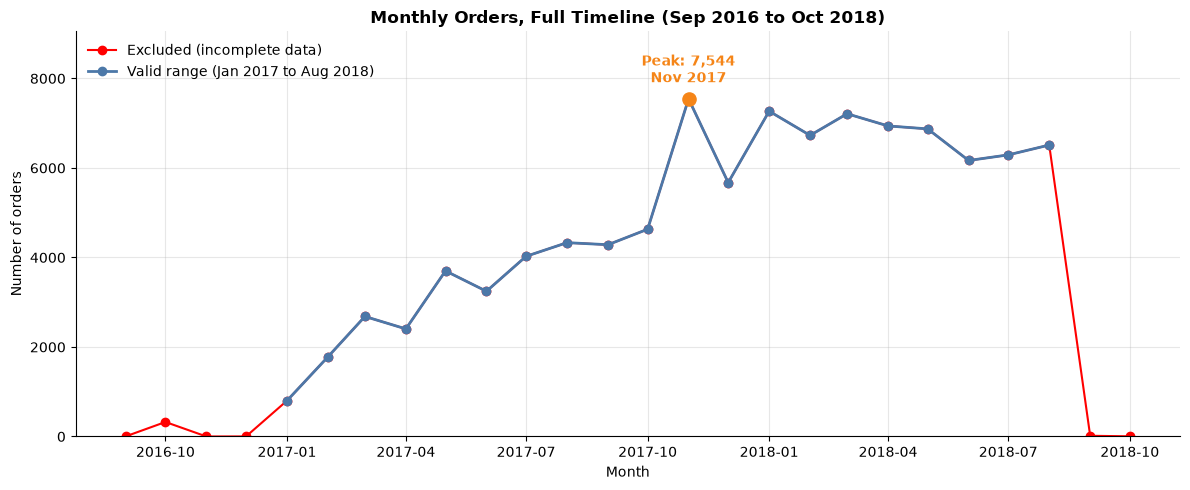

In [11]:
#monthly orders, full timeline chart
fig, ax = plt.subplots(figsize=(12, 5))

#whole timeline in red first, then the valid window in blue on top of it
ax.plot(timeline.index, timeline.values, marker="o", color="red", label="Excluded (incomplete data)")
ax.plot(valid.index, valid.values, marker="o", color="#4C78A8", linewidth=2,
        label="Valid range (Jan 2017 to Aug 2018)")

#mark the peak month
ax.scatter(max_date, max_val, color="#F58518", s=90, zorder=5)
ax.annotate(f"Peak: {max_val:,}\n{max_date.strftime('%b %Y')}", xy=(max_date, max_val),
            xytext=(0, 12), textcoords="offset points", ha="center",
            color="#F58518", fontweight="bold")

ax.set_ylim(0, max_val * 1.2)
ax.set_title("Monthly Orders, Full Timeline (Sep 2016 to Oct 2018)", fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Number of orders")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

In [12]:
#why the excluded months are excluded: statuses outside the valid window
excluded = con.sql("""
    select strftime(order_purchase_timestamp, '%Y-%m') as month, order_status, count(*) as orders
    from orders
    where order_purchase_timestamp < '2017-01-01' or order_purchase_timestamp >= '2018-09-01'
    group by month, order_status
    order by month, order_status
""").df()

#one row per month, one column per status
display(excluded.pivot(index="month", columns="order_status", values="orders").fillna(0).astype(int))

print("months with no orders at all:", timeline[timeline == 0].index.strftime("%Y-%m").tolist())

order_status,canceled,delivered,invoiced,processing,shipped,unavailable
month,,,,,,
2016-09,2,1,0,0,1,0
2016-10,24,265,18,2,8,7
2016-12,0,1,0,0,0,0
2018-09,15,0,0,0,1,0
2018-10,4,0,0,0,0,0


months with no orders at all: ['2016-11']


#### Black Friday check (daily orders)

top 5 days:


,orders
day,
2017-11-24,1176
2017-11-25,499
2017-11-27,403
2017-11-26,391
2017-11-28,380


typical day in Oct to mid-Nov 2017 (median): 158 orders
Black Friday 2017-11-24: 1,176 orders (7.5x a typical day)
November total: 7,544 orders, Black Friday weekend: 2,469, rest of November: 5,075


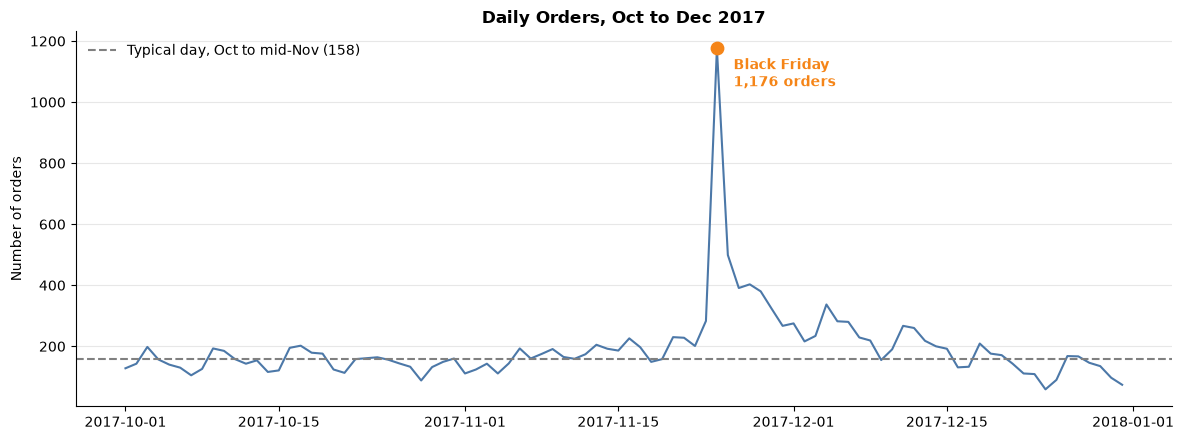

In [13]:
#daily orders from Oct to Dec 2017
daily = con.sql("""
    select cast(order_purchase_timestamp as date) as day, count(*) as orders
    from orders
    where order_purchase_timestamp >= '2017-10-01' and order_purchase_timestamp < '2018-01-01'
    group by day
    order by day
""").df()
daily["day"] = pd.to_datetime(daily["day"])
daily = daily.set_index("day")["orders"]

black_friday = pd.Timestamp("2017-11-24")
bf_orders = daily[black_friday]
typical = daily["2017-10-01":"2017-11-17"].median()   #a normal day before Black Friday

print("top 5 days:")
display(daily.sort_values(ascending=False).head(5).to_frame())
print(f"typical day in Oct to mid-Nov 2017 (median): {typical:.0f} orders")
print(f"Black Friday 2017-11-24: {bf_orders:,} orders ({bf_orders / typical:.1f}x a typical day)")

november = daily["2017-11-01":"2017-11-30"].sum()
bf_weekend = daily["2017-11-24":"2017-11-27"].sum()   #Black Friday weekend: Fri 24 to Mon 27
print(f"November total: {november:,} orders, Black Friday weekend: {bf_weekend:,}, rest of November: {november - bf_weekend:,}")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.index, daily.values, color="#4C78A8")
ax.axhline(typical, color="gray", linestyle="--", label=f"Typical day, Oct to mid-Nov ({typical:.0f})")
ax.scatter(black_friday, bf_orders, color="#F58518", s=80, zorder=5)
ax.annotate(f"Black Friday\n{bf_orders:,} orders", xy=(black_friday, bf_orders),
            xytext=(12, -6), textcoords="offset points", va="top",
            color="#F58518", fontweight="bold")
ax.set_title("Daily Orders, Oct to Dec 2017", fontweight="bold")
ax.set_ylabel("Number of orders")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

#### Monthly Orders: Conclusion (Q3)

**What is counted:** all orders **placed**, whatever their status (canceled and unavailable orders included). This measures demand. Later analyses of revenue or delivery should use delivered orders only.

**Valid window:** Jan 2017 to Aug 2018. The excluded months are artefacts of data collection, not real activity:
- Sep to Dec 2016: 329 orders in total. Nov 2016 has **no orders at all** and Dec 2016 has 1, so collection had a gap.
- Sep to Oct 2018: 20 orders in total, **all canceled except 1 shipped**. These are leftovers of the data cutoff.

**Highest and lowest months (valid window)**
- Highest: **November 2017** with **7,544** orders.
- Lowest: **January 2017** with **800** orders. This is the start of the ramp-up, not a real low. After the growth phase, the lowest month is June 2018 (6,167).

**Trend**
- **Growth (Jan to Oct 2017):** orders rose from 800 to 4,631 (about 5.8x), with small dips in April and June that recovered the next month.
- **Black Friday spike (Nov 2017):** orders jumped 63% in one month. The daily data confirms the cause: **Black Friday (2017-11-24) had 1,176 orders, 7.5x a typical day** (158), and the Black Friday weekend (24 to 27 Nov) alone brought 2,469 orders, about a third of the month.
- **Step-up, not only a spike:** even without the Black Friday weekend, November had 5,075 orders, already above October (4,631). From January 2018, orders stayed between about 6,200 and 7,300 per month, so volume moved to a higher level.
- **Plateau and slight decline (Dec 2017 to Aug 2018):** after the Dec 2017 drop (5,673), orders stayed between 6,167 and 7,269 per month, with the 2018 high in January and the low in June. The yearly comparison below measures this more precisely.

**Key takeaway:** orders grew strongly in 2017. Black Friday 2017 caused a large one-time spike, and volume also settled at a higher level afterwards. Growth then stalled, with a slow decline through mid-2018.

**Limitations**
- Only one full year (2017) is available, so **recurring** seasonality cannot be confirmed. The Black Friday spike itself is confirmed by the daily data, but whether it repeats every year is not.
- Order count measures volume only, not revenue, profit, or customer satisfaction.

### Yearly and Monthly Comparison (Q4)

In [14]:
#monthly orders inside the valid window only
valid_range = monthly_order[monthly_order["month_start"].between(START, END)]
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

display(valid_range[["month_start", "order_year", "order_month", "month_abbr", "orders_count"]])

,month_start,order_year,order_month,month_abbr,orders_count
3,2017-01-01,2017,1,Jan,800
4,2017-02-01,2017,2,Feb,1780
5,2017-03-01,2017,3,Mar,2682
6,2017-04-01,2017,4,Apr,2404
7,2017-05-01,2017,5,May,3700
8,2017-06-01,2017,6,Jun,3245
9,2017-07-01,2017,7,Jul,4026
10,2017-08-01,2017,8,Aug,4331
11,2017-09-01,2017,9,Sep,4285
12,2017-10-01,2017,10,Oct,4631


In [15]:
#best and worst month inside each year (2018 only has Jan to Aug)
for year in [2017, 2018]:
    year_data = valid_range[valid_range["order_year"] == year]
    best = year_data.loc[year_data["orders_count"].idxmax()]
    worst = year_data.loc[year_data["orders_count"].idxmin()]

    print(f"--- orders information in {year} ---")
    print(f"month with the most orders : {best['month_abbr']} with {best['orders_count']:,} orders")
    print(f"month with the least orders: {worst['month_abbr']} with {worst['orders_count']:,} orders\n")

--- orders information in 2017 ---
month with the most orders : Nov with 7,544 orders
month with the least orders: Jan with 800 orders

--- orders information in 2018 ---
month with the most orders : Jan with 7,269 orders
month with the least orders: Jun with 6,167 orders



In [16]:
#month-over-month % change (the first month has nothing to compare with, so it is NaN)
#orders per day removes the effect of month length (e.g. February has only 28 days)
per_day = valid / valid.index.days_in_month
mom_table = pd.DataFrame({
    "orders": valid,
    "mom_%": (valid.pct_change() * 100).round(1),
    "orders_per_day": per_day.round(1),
    "mom_per_day_%": (per_day.pct_change() * 100).round(1),
})
print("mom table:")
display(mom_table)

#how many months went up / down (2018 from Feb, so Jan 2018 vs Dec 2017 is not counted)
changes_2017 = mom_table.loc["2017", "mom_%"].dropna()
changes_2018 = mom_table.loc["2018-02":"2018-08", "mom_%"]
print(f"2017 (Feb to Dec): {(changes_2017 > 0).sum()} months up, {(changes_2017 < 0).sum()} months down")
print(f"2018 (Feb to Aug): {(changes_2018 > 0).sum()} months up, {(changes_2018 < 0).sum()} months down")

mom table:


,orders,mom_%,orders_per_day,mom_per_day_%
2017-01-01,800,NaN,25.8,NaN
2017-02-01,1780,122.5,63.6,146.3
2017-03-01,2682,50.7,86.5,36.1
2017-04-01,2404,-10.4,80.1,-7.4
2017-05-01,3700,53.9,119.4,48.9
2017-06-01,3245,-12.3,108.2,-9.4
2017-07-01,4026,24.1,129.9,20.1
2017-08-01,4331,7.6,139.7,7.6
2017-09-01,4285,-1.1,142.8,2.2
2017-10-01,4631,8.1,149.4,4.6


2017 (Feb to Dec): 7 months up, 4 months down
2018 (Feb to Aug): 3 months up, 4 months down


In [17]:
#year over year: compare the same months only (Jan to Aug, because 2018 stops in Aug)
yoy = pd.DataFrame({
    "2017": timeline["2017-01-01":"2017-08-01"].values,
    "2018": timeline["2018-01-01":"2018-08-01"].values,
}, index=month_labels[:8])
yoy["yoy_%"] = ((yoy["2018"] / yoy["2017"] - 1) * 100).round(1)
print("yoy table:")
display(yoy)

print("fair yearly comparison, Jan to Aug only:")
print(f"2017: total {yoy['2017'].sum():,} orders, average {yoy['2017'].mean():,.0f} per month")
print(f"2018: total {yoy['2018'].sum():,} orders, average {yoy['2018'].mean():,.0f} per month")
print(f"change: {(yoy['2018'].sum() / yoy['2017'].sum() - 1) * 100:+.0f}%")

yoy table:


,2017,2018,yoy_%
Jan,800,7269,808.6
Feb,1780,6728,278.0
Mar,2682,7211,168.9
Apr,2404,6939,188.6
May,3700,6873,85.8
Jun,3245,6167,90.0
Jul,4026,6292,56.3
Aug,4331,6512,50.4


fair yearly comparison, Jan to Aug only:
2017: total 22,968 orders, average 2,871 per month
2018: total 53,991 orders, average 6,749 per month
change: +135%


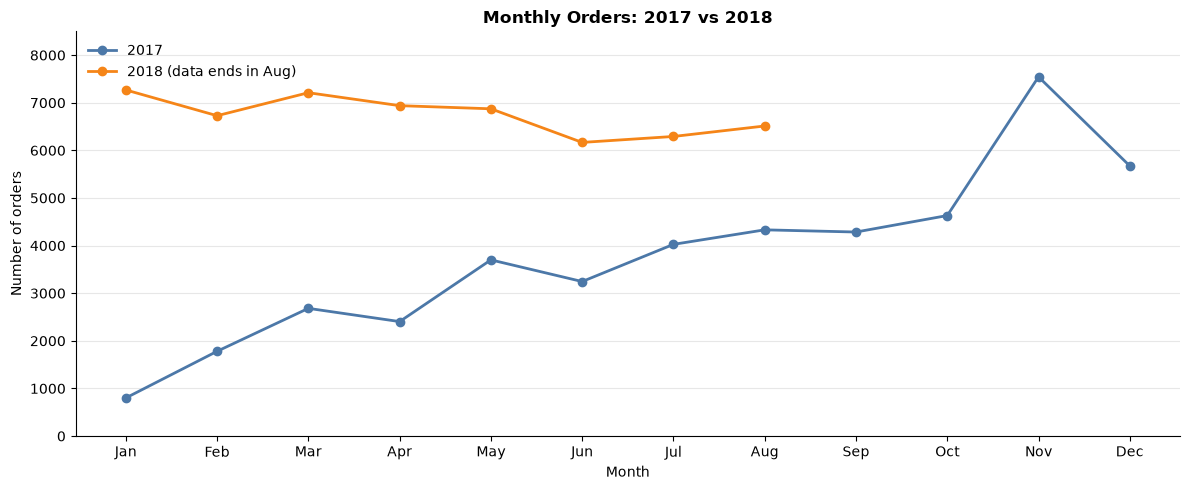

In [18]:
#chart: 2017 vs 2018, one line per year, months on the x axis
orders_2017 = valid_range[valid_range["order_year"] == 2017]
orders_2018 = valid_range[valid_range["order_year"] == 2018]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(orders_2017["order_month"], orders_2017["orders_count"], marker="o", color="#4C78A8", linewidth=2, label="2017")
ax.plot(orders_2018["order_month"], orders_2018["orders_count"], marker="o", color="#F58518", linewidth=2, label="2018 (data ends in Aug)")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set_ylim(0, 8500)
ax.set_title("Monthly Orders: 2017 vs 2018", fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Number of orders")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

#### Yearly and Monthly Comparison: Conclusion (Q4)

**Question:** has the store's activity increased over the period?

**Answer:** yes over the whole period, but **not anymore in 2018**: all the growth happened in 2017, and 2018 was flat with a slight decline.

**Evidence**
- **Year over year (Jan to Aug, same months):** 2018 was higher than 2017 in all 8 months. Total orders rose from 22,968 to 53,991 (**+135%**), from an average of 2,871 to 6,749 orders per month. This is expected, because 2017 was the ramp-up year.
- **The gap is shrinking:** the YoY (Year over Year = (this year's value / last year's value − 1) × 100) increase fell from +809% (Jan) to +50% (Aug), because 2017 kept growing while 2018 stayed flat.
- **2017:** orders grew from 800 (Jan) to 4,631 (Oct), then jumped 63% in Nov (7,544, driven by Black Friday). Increases outnumbered decreases (7 months up, 4 down).
- **2018:** orders stayed between 6,167 and 7,269 per month. From February to August there were 3 months up and 4 down. Per day (which removes the effect of month length), orders fell from a peak of 240 (Feb) to about 210 (Aug), roughly **−12%**.

**Decision:** order activity increased clearly over the dataset period, with a step-up around Nov 2017. After that, volume stabilized at about 6,200 to 7,300 orders per month, with a slight downward drift in 2018 rather than continued growth. Whether this is a temporary plateau or a real slowdown would need data after Aug 2018.

**Limitations**
- 2018 data is available only through August, so full-year totals are not comparable between years.
- Only one full year exists, so seasonality can't be confirmed.
- Order count shows volume only, not revenue or customer satisfaction.

### Orders by Day of Week (Q5)

In [19]:
#number of orders on each day of the week (valid window only, Monday = 1 ... Sunday = 7)
weekday = con.sql("""
    select isodow(order_purchase_timestamp) as day_number,
           dayname(order_purchase_timestamp) as day_name,
           count(*) as orders
    from orders
    where order_purchase_timestamp >= '2017-01-01' and order_purchase_timestamp < '2018-09-01'
    group by day_number, day_name
    order by day_number
""").df()

weekday["percent"] = weekday["orders"] / weekday["orders"].sum() * 100
#how far each day is from the average day (+10 means 10% more orders than average)
weekday["vs_average_%"] = (weekday["orders"] / weekday["orders"].mean() - 1) * 100
display(weekday.round(1))

busiest = weekday.loc[weekday["orders"].idxmax()]
quietest = weekday.loc[weekday["orders"].idxmin()]
print(f"busiest day : {busiest['day_name']} with {busiest['orders']:,} orders")
print(f"quietest day: {quietest['day_name']} with {quietest['orders']:,} orders")
print(f"the busiest day has {busiest['orders'] / quietest['orders']:.2f}x the orders of the quietest day")

#weekdays (Mon to Fri) vs weekend (Sat, Sun), as average orders per day
weekdays_avg = weekday[weekday["day_number"] <= 5]["orders"].mean()
weekend_avg = weekday[weekday["day_number"] >= 6]["orders"].mean()
print(f"average weekday (Mon-Fri): {weekdays_avg:,.0f} orders, average weekend day: {weekend_avg:,.0f} orders")

,day_number,day_name,orders,percent,vs_average_%
0,1,Monday,16141,16.3,14.0
1,2,Tuesday,15896,16.0,12.3
2,3,Wednesday,15501,15.6,9.5
3,4,Thursday,14704,14.8,3.9
4,5,Friday,14075,14.2,-0.6
5,6,Saturday,10843,10.9,-23.4
6,7,Sunday,11932,12.0,-15.7


busiest day : Monday with 16,141 orders
quietest day: Saturday with 10,843 orders
the busiest day has 1.49x the orders of the quietest day
average weekday (Mon-Fri): 15,263 orders, average weekend day: 11,388 orders


In [20]:
#each weekday appears 86 or 87 times in the valid window, so the totals are fair to compare
days_in_window = pd.date_range("2017-01-01", "2018-08-31")
print("how many times each weekday appears in the window:")
print(days_in_window.day_name().value_counts().to_string())

how many times each weekday appears in the window:
Sunday       87
Monday       87
Tuesday      87
Wednesday    87
Thursday     87
Friday       87
Saturday     86


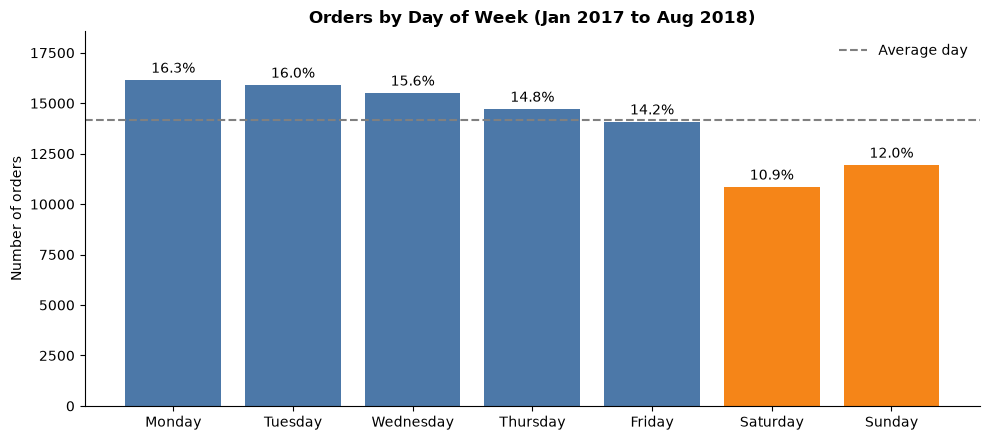

In [21]:
#chart: orders by day of week
fig, ax = plt.subplots(figsize=(10, 4.5))

#weekend days in a different color
colors = ["#4C78A8" if n <= 5 else "#F58518" for n in weekday["day_number"]]
bars = ax.bar(weekday["day_name"], weekday["orders"], color=colors)
ax.bar_label(bars, labels=[f"{p:.1f}%" for p in weekday["percent"]], padding=3)
ax.axhline(weekday["orders"].mean(), color="gray", linestyle="--", label="Average day")

ax.set_title("Orders by Day of Week (Jan 2017 to Aug 2018)", fontweight="bold")
ax.set_ylabel("Number of orders")
ax.set_ylim(0, weekday["orders"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

#### Orders by Day of Week: Conclusion (Q5)

Each weekday appears 86 or 87 times in the valid window, so the totals can be compared directly.

- **Busiest days:** Monday (16,141 orders, 16.3%), Tuesday (16.0%) and Wednesday (15.6%). Monday is 14% above an average day.
- **Quietest days:** Saturday (10,843 orders, 10.9%, 23% below average) and Sunday (12.0%).
- Orders **fall steadily from Monday to Friday**, then drop sharply on the weekend. Friday is slightly below average even though it includes Black Friday (1,176 orders on one day).
- **Weekday vs weekend:** an average weekday has 15,263 orders and an average weekend day 11,388, so weekdays get about **34% more orders**. The busiest day (Monday) has **1.49x** the orders of the quietest day (Saturday).

**Is the difference significant?** Yes. The gap between weekdays and weekends is large (about a third) and the pattern is very regular, so it is not random noise.

**Business insight:** customers shop mostly at the start of the week. Promotions and ads should target Monday to Wednesday to catch peak demand. Support and logistics teams need the most capacity on those days, and the weekend is the quietest time for maintenance or system updates.

### Top 5 Months (Q6)

In [22]:
#5 months with the most orders (valid window only)
top_5 = valid_range.sort_values("orders_count", ascending=False).head(5)
display(top_5[["order_year", "month_abbr", "orders_count"]].reset_index(drop=True))

print("how many of the top 5 months come from each year:")
print(top_5["order_year"].value_counts().to_string())

,order_year,month_abbr,orders_count
0,2017,Nov,7544
1,2018,Jan,7269
2,2018,Mar,7211
3,2018,Apr,6939
4,2018,May,6873


how many of the top 5 months come from each year:
order_year
2018    4
2017    1


#### Top 5 Months: Conclusion (Q6)

The 5 months with the most orders are **Nov 2017 (7,544), Jan 2018 (7,269), Mar 2018 (7,211), Apr 2018 (6,939) and May 2018 (6,873)**.

- **4 of the 5 are from 2018** and only 1 is from 2017. All of them are from **Nov 2017 onwards**, the later part of the window.
- So the top months are **not spread across years**. They reflect the higher order level reached after Nov 2017, not a month that is strong every year.
- **Nov 2017 is the exception:** it is the only top month driven by a one-time event (Black Friday). The four 2018 months are simply normal months at the new, higher level.

### Business Conclusion

**What changed in Olist's activity?**
1. **Fast growth in 2017:** monthly orders grew from 800 (Jan 2017) to 4,631 (Oct 2017), about 5.8x in ten months.
2. **A step-up in Nov 2017:** Black Friday (1,176 orders in one day, 7.5x a normal day) made Nov 2017 the record month (7,544), and order volume stayed at a higher level afterwards.
3. **A plateau in 2018:** orders stayed between about 6,200 and 7,300 per month. Per day, they fell about 12% from February to August 2018.
4. **Reliable delivery:** 97% of orders were delivered. Only 1.24% failed (canceled or unavailable), about half of them because the product was unavailable.
5. **A clear weekly pattern:** customers order most on Monday to Wednesday and least on the weekend (weekdays get about 34% more orders).

**Is there enough evidence for sustained growth?** **No.** There was strong growth, but only in 2017. In 2018, volume stopped growing and drifted slightly down, and the data ends in Aug 2018. The data shows growth followed by a plateau, not sustained growth.

**Is there a seasonal pattern?**
- **Yearly seasonality: not enough evidence.** The dataset has only one full year (2017), so we cannot check whether any month is strong every year. The Nov 2017 Black Friday spike is real (confirmed by daily data), but one year cannot prove it repeats.
- **Weekly pattern: yes.** The weekday vs weekend difference is large and appears across the whole 20-month window.

**Recommendations**
- Investigate why growth stopped in 2018 (competition, marketing spend, seller supply) before planning further growth.
- Prepare stock, sellers and logistics for Black Friday, which was by far the biggest single sales day.
- Reduce "unavailable" orders by improving stock availability, since they cause about half of all failed orders.
- Schedule campaigns for the start of the week, when demand is highest.

In [23]:
con.close()